# 3rd project of Internship at CodeAlpha

Projet name: "CodeAlpha_Car_Price_Prediction"

Requrements:

● Collect car-related features like brand goodwill, horsepower, mileage, etc.

● Train a regression model to predict car prices based on these features.

● Handle data preprocessing, feature engineering, and model evaluation

● Use Python libraries like Pandas, Scikit-learn and Matplotlib for the workflow.

● Understand real-world applications of machine learning in price prediction.

Step 1 — Upload and inspect the data

In [48]:

# Step 1: Import the required library
import pandas as pd
from google.colab import files

# Step 2: Upload the downloaded CSV file
df = pd.read_csv("/content/car data.csv")

# Step 3: Display the first few rows of the dataset
print(df.head())


  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0  


In [49]:

# 1. Check the dataset dimensions
print("Dataset shape:", df.shape)

# 2. Display the actual column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Display the first five rows
display(df.head())

# 4. Check data types
print("\nData types:")
print(df.dtypes)

# 5. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 6. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 7. Get a statistical summary
display(df.describe())


Dataset shape: (301, 9)

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0



Data types:
Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type         object
Selling_type      object
Transmission      object
Owner              int64
dtype: object

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Number of duplicate rows: 2


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


# Step 2 : EDA

Step 2.1 — Understand the data distribution

Dataset shape: (301, 9)

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


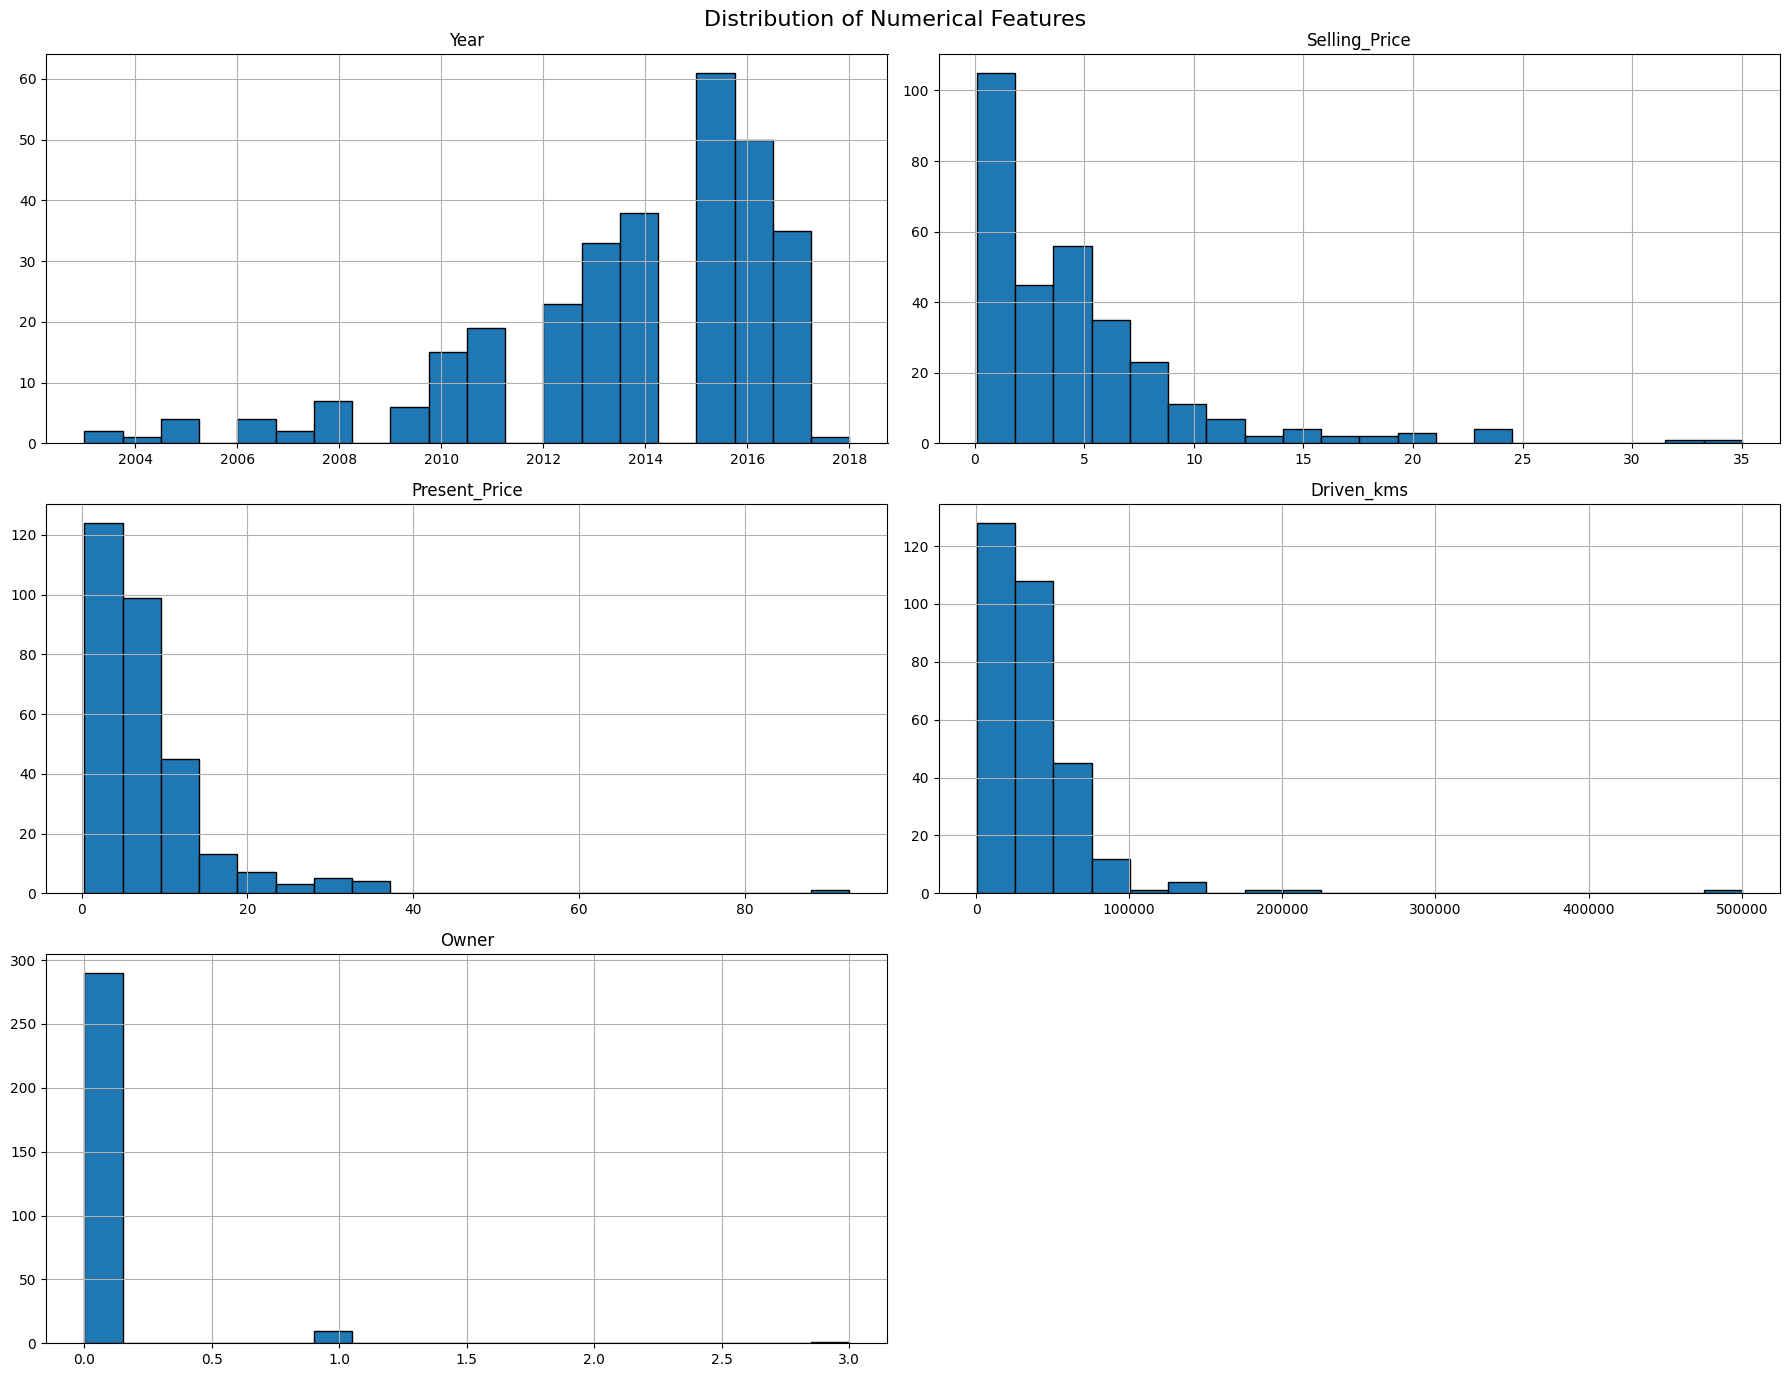

In [50]:

import matplotlib.pyplot as plt
import seaborn as sns

# Display basic information
print("Dataset shape:", df.shape)
print("\nStatistical summary:")
display(df.describe(include="all").T)

# Visualize the distribution of numerical features
df.hist(figsize=(18, 14), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


Step 2.2 — Identify the target variable

In [51]:

print("All columns:")
for column in df.columns:
    print(column)

print("\nPossible price-related columns:")
print([
    column for column in df.columns
    if "price" in column.lower()
])


All columns:
Car_Name
Year
Selling_Price
Present_Price
Driven_kms
Fuel_Type
Selling_type
Transmission
Owner

Possible price-related columns:
['Selling_Price', 'Present_Price']


Step 2.3 — Visualize the car price distribution

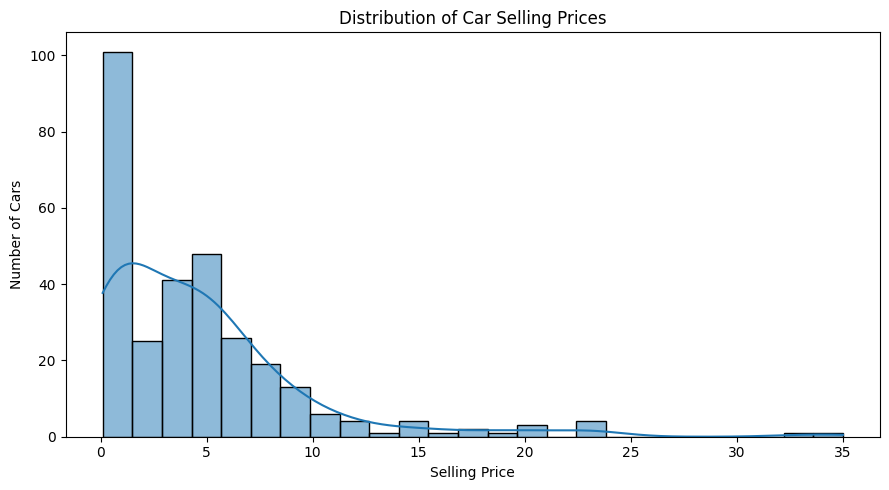

Lowest selling price: 0.1
Highest selling price: 35.0
Average selling price: 4.661295681063123
Median selling price: 3.6


In [52]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of selling prices
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Selling_Price",
    kde=True,
    bins=25
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

# Calculate important price statistics
print("Lowest selling price:", df["Selling_Price"].min())
print("Highest selling price:", df["Selling_Price"].max())
print("Average selling price:", df["Selling_Price"].mean())
print("Median selling price:", df["Selling_Price"].median())


Step 2.4 — Analyze how present price relates to selling price

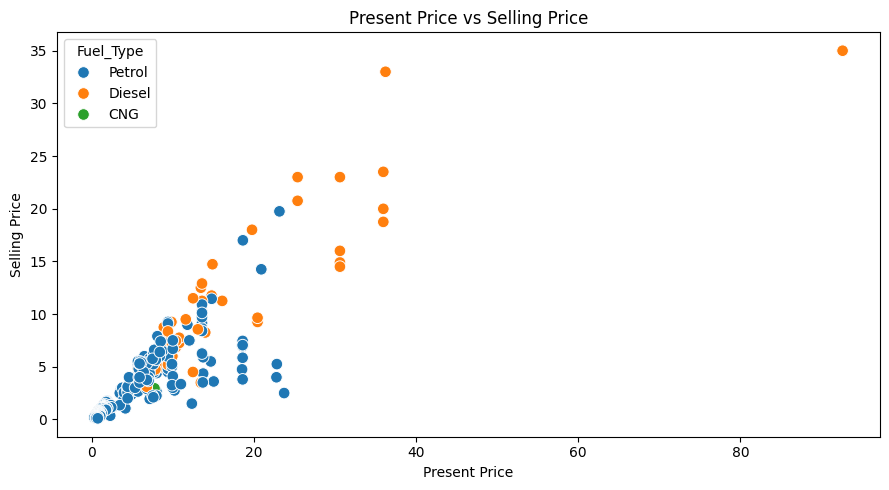

Correlation between Present Price and Selling Price: 0.8789


In [53]:

import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot: Present Price vs Selling Price
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Present_Price",
    y="Selling_Price",
    hue="Fuel_Type",
    s=70
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

# Calculate the correlation
correlation = df["Present_Price"].corr(df["Selling_Price"])

print("Correlation between Present Price and Selling Price:",
      round(correlation, 4))


Step 2.5 — Analyze the effect of car age

Current year: 2026

Car age summary:
count    301.000000
mean      12.372093
std        2.891554
min        8.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       23.000000
Name: Car_Age, dtype: float64


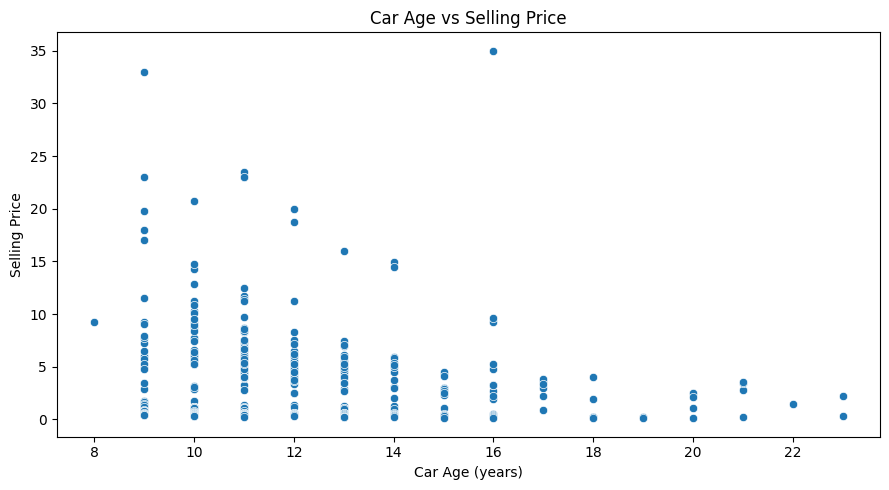

In [54]:

import datetime

# Calculate car age using the current year
current_year = datetime.datetime.now().year

df["Car_Age"] = current_year - df["Year"]

print("Current year:", current_year)
print("\nCar age summary:")
print(df["Car_Age"].describe())

# Visualize car age against selling price
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price"
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()


Step 2.6 — Driven kilometers vs selling price

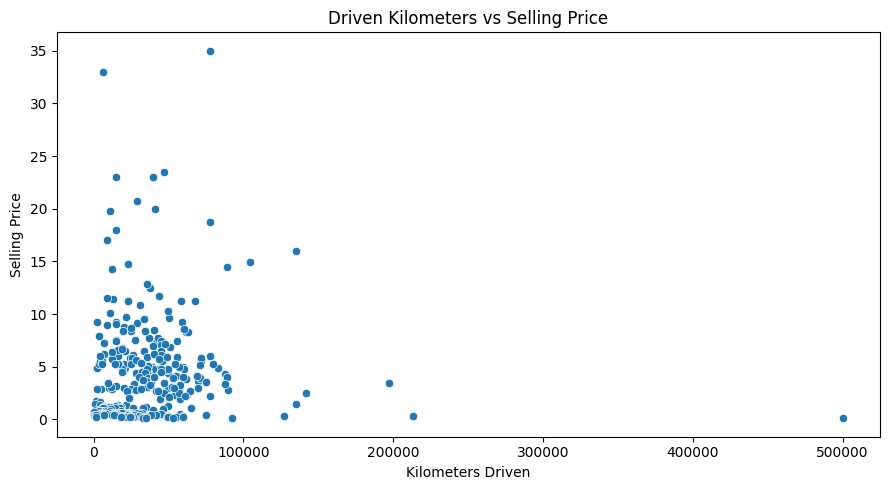

In [55]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Driven_kms",
    y="Selling_Price"
)

plt.title("Driven Kilometers vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()


Step 2.7 — Selling price by fuel type

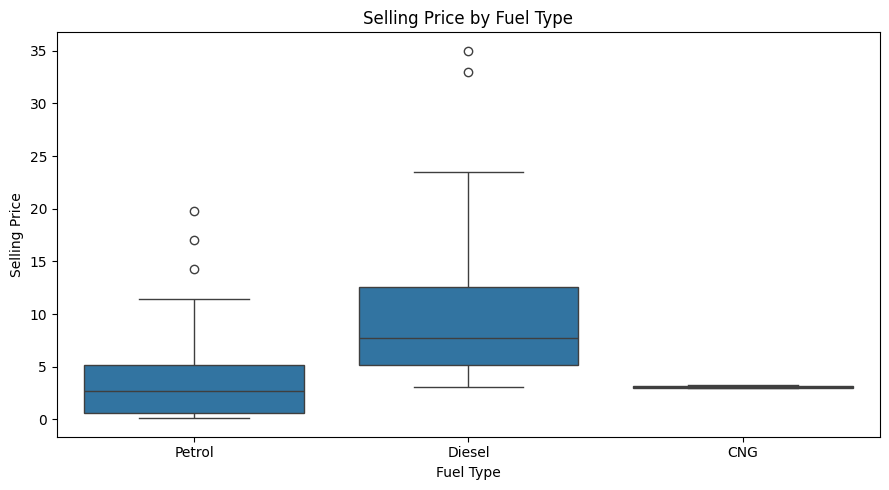

In [56]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()


Step 2.8 — Selling price by transmission type

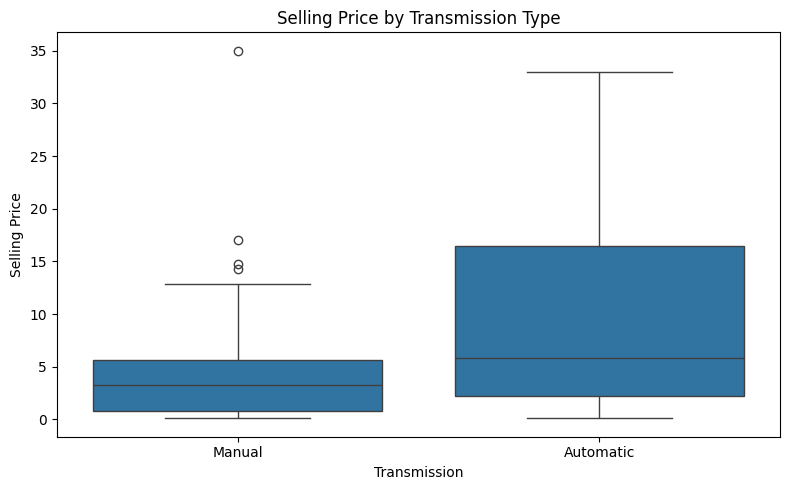

In [57]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Transmission",
    y="Selling_Price"
)

plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()


Step 2.9 — Selling price by number of previous owners

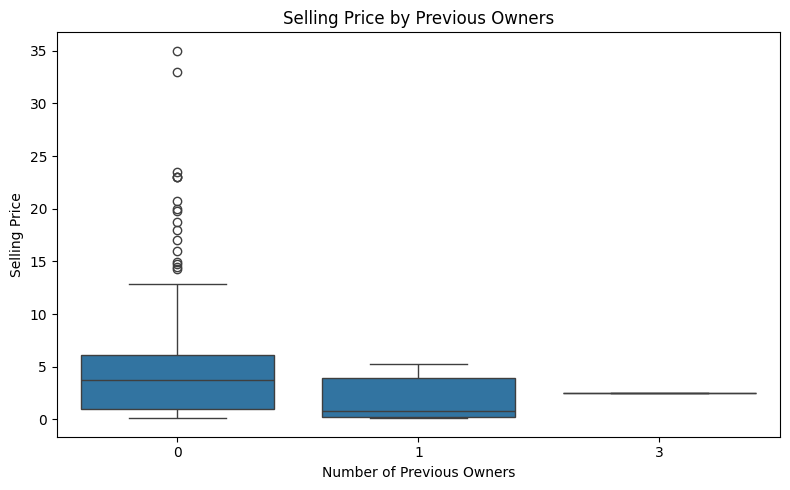

In [58]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Owner",
    y="Selling_Price"
)

plt.title("Selling Price by Previous Owners")
plt.xlabel("Number of Previous Owners")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()


# Step 3 : Data Preprocessing and Feature Engineering

In [59]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check categorical values
for column in ["Fuel_Type", "Selling_type", "Transmission", "Owner"]:
    print(f"\nUnique values in {column}:")
    print(df[column].value_counts(dropna=False))


Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
Car_Age          0
dtype: int64

Duplicate rows: 2

Data types:
Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type         object
Selling_type      object
Transmission      object
Owner              int64
Car_Age            int64
dtype: object

Unique values in Fuel_Type:
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

Unique values in Selling_type:
Selling_type
Dealer        195
Individual    106
Name: count, dtype: int64

Unique values in Transmission:
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

Unique values in Owner:
Owner
0    290
1     10
3      1
Name: count, dtype: int64


Step 3.1 — Prepare the dataset

In [60]:

import pandas as pd

# Work on a copy so the original dataset remains unchanged
df_model = df.copy()

# Remove accidental spaces from column names
df_model.columns = df_model.columns.str.strip()

# Check the dataset structure
print("Dataset shape:", df_model.shape)
print("\nColumns:")
print(df_model.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df_model.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df_model.duplicated().sum())

# Check data types
print("\nData types:")
print(df_model.dtypes)


Dataset shape: (301, 10)

Columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner', 'Car_Age']

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
Car_Age          0
dtype: int64

Duplicate rows: 2

Data types:
Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type         object
Selling_type      object
Transmission      object
Owner              int64
Car_Age            int64
dtype: object


Step 3.2 — Create the car-age feature

In [61]:
from datetime import datetime

# Create car age from the manufacturing year
current_year = datetime.now().year

df_model["Car_Age"] = current_year - df_model["Year"]

print("Reference year:", current_year)
print("\nCar age preview:")
display(df_model[["Year", "Car_Age"]].head())

print("\nCar age statistics:")
print(df_model["Car_Age"].describe())


Reference year: 2026

Car age preview:


,Year,Car_Age
0,2014,12
1,2013,13
2,2017,9
3,2011,15
4,2014,12



Car age statistics:
count    301.000000
mean      12.372093
std        2.891554
min        8.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       23.000000
Name: Car_Age, dtype: float64


Step 3.3 — Select the features and target

In [62]:

# Define the target variable
target = "Selling_Price"

# Select predictor columns
features = [
    "Present_Price",
    "Driven_kms",
    "Fuel_Type",
    "Selling_type",
    "Transmission",
    "Owner",
    "Car_Age"
]

# Create X (features) and y (target)
X = df_model[features].copy()
y = df_model[target].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget preview:")
display(y.head())


Feature matrix shape: (301, 7)
Target shape: (301,)

Feature columns:
['Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner', 'Car_Age']

Target preview:


,Selling_Price
0,3.35
1,4.75
2,7.25
3,2.85
4,4.60


Step 3.4 — Prepare the features and target

In [63]:

import pandas as pd
from datetime import datetime

# Work on a copy so the original dataset stays unchanged
df_model = df.copy()

# Remove accidental spaces from column names
df_model.columns = df_model.columns.str.strip()

# Create a new feature: car age
current_year = datetime.now().year
df_model["Car_Age"] = current_year - df_model["Year"]

# Select input features
features = [
    "Present_Price",
    "Driven_kms",
    "Fuel_Type",
    "Selling_type",
    "Transmission",
    "Owner",
    "Car_Age"
]

X = df_model[features]
y = df_model["Selling_Price"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nMissing values in features:")
print(X.isnull().sum())
print("\nMissing values in target:", y.isnull().sum())
print("\nFeature data types:")
print(X.dtypes)


Feature matrix shape: (301, 7)
Target shape: (301,)

Missing values in features:
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
Car_Age          0
dtype: int64

Missing values in target: 0

Feature data types:
Present_Price    float64
Driven_kms         int64
Fuel_Type         object
Selling_type      object
Transmission      object
Owner              int64
Car_Age            int64
dtype: object


# Step 4: Split the data and build the preprocessing pipeline

In [64]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Remove rows where the target price is missing
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Identify numerical and categorical features
numeric_features = ["Present_Price", "Driven_kms", "Owner", "Car_Age"]
categorical_features = ["Fuel_Type", "Selling_type", "Transmission"]

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 240
Testing rows: 61


# Step 5: Random Forest regression model


In [65]:
# Create the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict car prices for test data
y_pred = model.predict(X_test)

print("Model training completed!")


Model training completed!


# Step 6 : Evaluate the model

In [66]:

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R² Score: {r2:.3f}")


Mean Absolute Error (MAE): 0.637
Root Mean Squared Error (RMSE): 0.975
R² Score: 0.959


# Step 7: Data visualization

actual car price vs predicted car price

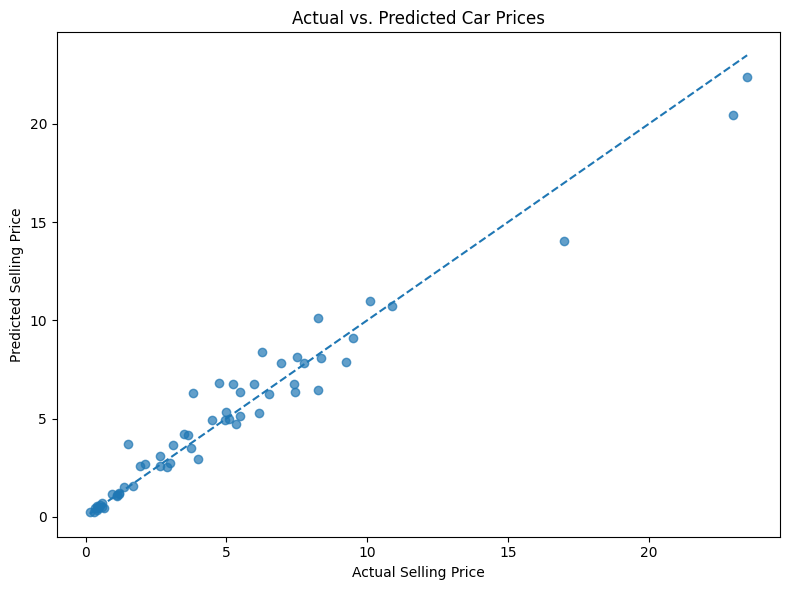

In [67]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs. Predicted Car Prices")
plt.tight_layout()
plt.show()


Prediction errors

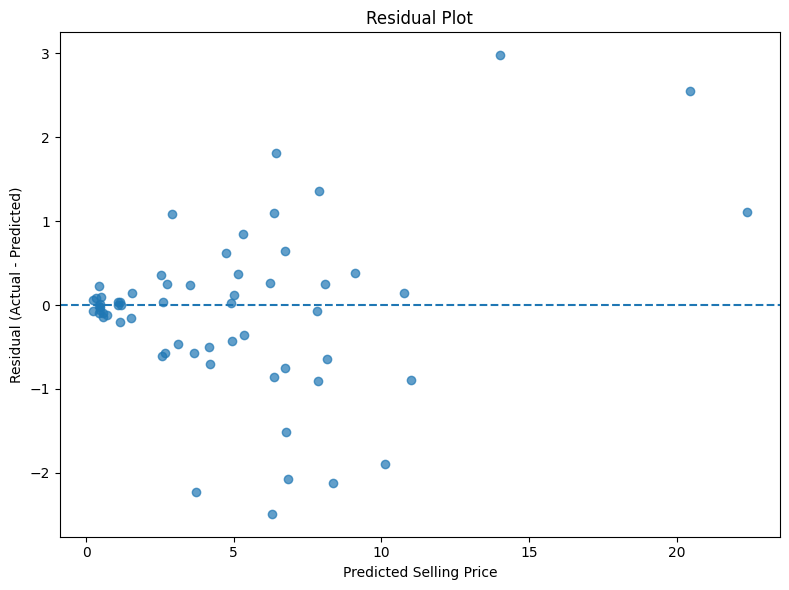

In [68]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()


most important feature

                     Feature  Importance
          num__Present_Price    0.886373
                num__Car_Age    0.057162
             num__Driven_kms    0.033753
    cat__Transmission_Manual    0.007660
 cat__Transmission_Automatic    0.004851
       cat__Fuel_Type_Diesel    0.003883
       cat__Fuel_Type_Petrol    0.002595
cat__Selling_type_Individual    0.002111
    cat__Selling_type_Dealer    0.001209
                  num__Owner    0.000390
          cat__Fuel_Type_CNG    0.000013


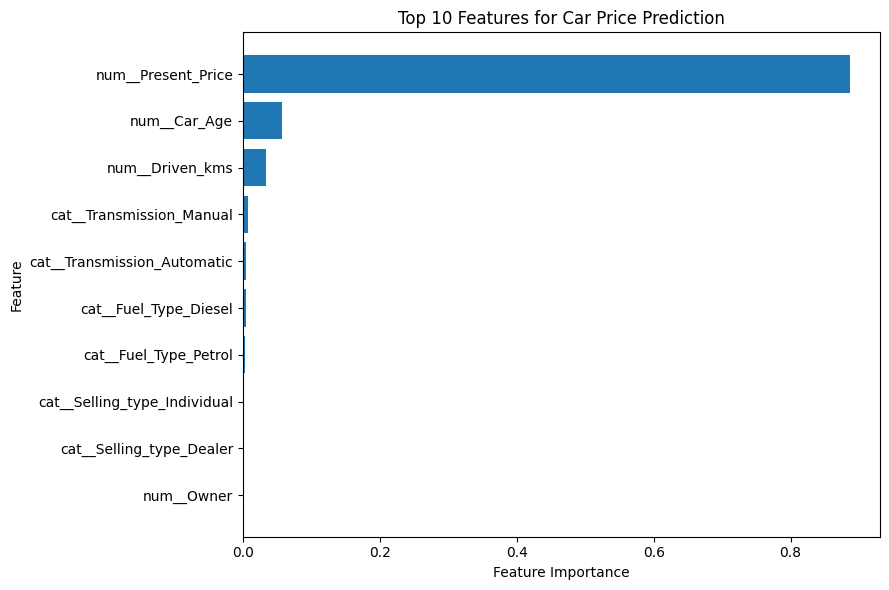

In [69]:

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get importance scores from the trained Random Forest
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df.to_string(index=False))

# Plot the 10 most important features
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features for Car Price Prediction")
plt.tight_layout()
plt.show()


Compare three regression models

In [70]:

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define the models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

comparison_results = []

for name, regressor in models.items():
    # Give each model its own preprocessing pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("regressor", regressor)
    ])

    # Train and predict
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    # Calculate metrics
    comparison_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("RMSE")

print(comparison_df.round(4).to_string(index=False))


            Model    MAE   RMSE  R2 Score
    Random Forest 0.6368 0.9748    0.9587
    Decision Tree 0.8208 1.4003    0.9149
Linear Regression 1.2164 1.8658    0.8489
